# TUGAS BASIS DATA

## SISTEM BASIS DATA PERPUSTAKAAN MENGGUNAKAN SQLITE DI GOOGLE COLAB

**Nama:** Dini Ira Sokmawati

**Mata Kuliah:** Analitik dan Visualisasi Data

**Platform:** Google Colab

**Database:** SQLite

**Bahasa Pemrograman:** Python

---



In [ ]:

# 1. Mengimpor library SQLite

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# 2. Membuat koneksi database
conn = sqlite3.connect('perpustakaan.db')

# 3. Membuat cursor
cursor = conn.cursor()

print("Database perpustakaan berhasil dibuat!")


Database perpustakaan berhasil dibuat!


In [ ]:

# Membuat tabel buku
cursor.execute("""
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
)
""")

# Membuat tabel anggota
cursor.execute("""
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL
)
""")

# Membuat tabel peminjaman
cursor.execute("""
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
""")

# Mengaktifkan foreign key
cursor.execute("PRAGMA foreign_keys = ON")

# Menyimpan perubahan database
conn.commit()

print("Ketiga tabel berhasil dibuat!")


Ketiga tabel berhasil dibuat!


In [ ]:

# Memasukkan 5 data buku ke tabel buku

data_buku = [
    (1, 'Laskar Pelangi', 'Andrea Hirata', 2005),
    (2, 'Bumi', 'Tere Liye', 2014),
    (3, 'Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    (4, 'Pulang', 'Tere Liye', 2015),
    (5, 'Filosofi Teras', 'Henry Manampiring', 2018)
]

cursor.executemany("""
INSERT INTO buku (id, judul, penulis, tahun)
VALUES (?, ?, ?, ?)
""", data_buku)

conn.commit()

print("5 data buku berhasil ditambahkan!")


5 data buku berhasil ditambahkan!


In [ ]:

# Memasukkan 3 data anggota ke tabel anggota

data_anggota = [
    (1, 'Dini Ira Sokmawati', 'dini@gmail.com'),
    (2, 'Andi Pratama', 'andi@gmail.com'),
    (3, 'Siti Rahmawati', 'siti@gmail.com')
]

cursor.executemany("""
INSERT INTO anggota (id, nama, email)
VALUES (?, ?, ?)
""", data_anggota)

conn.commit()

print("3 data anggota berhasil ditambahkan!")


3 data anggota berhasil ditambahkan!


In [ ]:

# Menampilkan seluruh data buku
print("DAFTAR BUKU")
display(pd.read_sql_query("SELECT * FROM buku", conn))

# Menampilkan seluruh data anggota
print("DAFTAR ANGGOTA")
display(pd.read_sql_query("SELECT * FROM anggota", conn))


DAFTAR BUKU


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi,Tere Liye,2014
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Pulang,Tere Liye,2015
4,5,Filosofi Teras,Henry Manampiring,2018


DAFTAR ANGGOTA


,id,nama,email
0,1,Dini Ira Sokmawati,dini@gmail.com
1,2,Andi Pratama,andi@gmail.com
2,3,Siti Rahmawati,siti@gmail.com


In [ ]:

# Memasukkan 4 transaksi peminjaman

data_peminjaman = [
    (1, 1, 1, '2026-11-01', '2026-11-05'),
    (2, 2, 2, '2026-11-03', '2026-11-08'),
    (3, 3, 3, '2026-11-05', None),
    (4, 1, 5, '2026-11-10', '2026-11-15')
]

cursor.executemany("""
INSERT INTO peminjaman
(id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?, ?)
""", data_peminjaman)

conn.commit()

print("4 transaksi peminjaman berhasil ditambahkan!")


4 transaksi peminjaman berhasil ditambahkan!


In [ ]:

# Menampilkan seluruh data peminjaman

df_peminjaman = pd.read_sql_query(
    "SELECT * FROM peminjaman",
    conn
)

display(df_peminjaman)


,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-05
1,2,2,2,2026-11-03,2026-11-08
2,3,3,3,2026-11-05,None
3,4,1,5,2026-11-10,2026-11-15


In [ ]:

# Menampilkan daftar peminjaman menggunakan JOIN

query_join = """
SELECT
    peminjaman.id AS ID_Peminjaman,
    anggota.nama AS Nama_Anggota,
    buku.judul AS Judul_Buku,
    peminjaman.tgl_pinjam AS Tanggal_Pinjam,
    peminjaman.tgl_kembali AS Tanggal_Kembali
FROM peminjaman
INNER JOIN anggota
    ON peminjaman.id_anggota = anggota.id
INNER JOIN buku
    ON peminjaman.id_buku = buku.id
"""

# Mengambil hasil query ke dalam DataFrame
df_join = pd.read_sql_query(query_join, conn)

# Menampilkan hasil
display(df_join)


,ID_Peminjaman,Nama_Anggota,Judul_Buku,Tanggal_Pinjam,Tanggal_Kembali
0,1,Dini Ira Sokmawati,Laskar Pelangi,2026-11-01,2026-11-05
1,2,Andi Pratama,Bumi,2026-11-03,2026-11-08
2,3,Siti Rahmawati,Negeri 5 Menara,2026-11-05,None
3,4,Dini Ira Sokmawati,Filosofi Teras,2026-11-10,2026-11-15


**Hasil Penggabungan Data Menggunakan JOIN**

Berdasarkan hasil query SQL menggunakan INNER JOIN, tabel peminjaman berhasil digabungkan dengan tabel anggota dan tabel buku. Hasil penggabungan menampilkan informasi berupa ID peminjaman, nama anggota, judul buku, tanggal peminjaman, dan tanggal pengembalian.

Dari hasil tersebut diperoleh sebanyak 4 transaksi peminjaman buku. Dengan menggunakan JOIN, informasi yang sebelumnya tersimpan secara terpisah dalam beberapa tabel dapat ditampilkan menjadi satu daftar peminjaman yang lebih mudah dipahami.

In [ ]:

# Menghitung jumlah buku yang dipinjam oleh masing-masing anggota

query_group = """
SELECT
    anggota.nama AS Nama_Anggota,
    COUNT(peminjaman.id_buku) AS Jumlah_Buku_Dipinjam
FROM anggota
LEFT JOIN peminjaman
    ON anggota.id = peminjaman.id_anggota
GROUP BY anggota.id, anggota.nama
ORDER BY anggota.id
"""

# Mengambil hasil query ke DataFrame
df_group = pd.read_sql_query(query_group, conn)

# Menampilkan hasil
display(df_group)


,Nama_Anggota,Jumlah_Buku_Dipinjam
0,Dini Ira Sokmawati,2
1,Andi Pratama,1
2,Siti Rahmawati,1


**Hasil Perhitungan Jumlah Peminjaman Menggunakan GROUP BY**

Berdasarkan hasil query SQL menggunakan fungsi agregasi COUNT() dan GROUP BY, diperoleh informasi jumlah buku yang dipinjam oleh masing-masing anggota. Dini Ira Sokmawati melakukan peminjaman sebanyak 2 buku, sedangkan Andi Pratama dan Siti Rahmawati masing-masing melakukan peminjaman sebanyak 1 buku.

Dengan demikian, total keseluruhan transaksi peminjaman yang tercatat dalam database adalah 4 transaksi. Penggunaan GROUP BY memudahkan proses pengelompokan dan perhitungan jumlah peminjaman berdasarkan masing-masing anggota.

In [ ]:

# Membuat DataFrame dari hasil query SQL

query_dataframe = """
SELECT
    peminjaman.id AS ID_Peminjaman,
    anggota.nama AS Nama_Anggota,
    buku.judul AS Judul_Buku,
    buku.penulis AS Penulis,
    peminjaman.tgl_pinjam AS Tanggal_Pinjam,
    peminjaman.tgl_kembali AS Tanggal_Kembali
FROM peminjaman
INNER JOIN anggota
    ON peminjaman.id_anggota = anggota.id
INNER JOIN buku
    ON peminjaman.id_buku = buku.id
"""

df = pd.read_sql_query(query_dataframe, conn)

# Menampilkan DataFrame
display(df)


,ID_Peminjaman,Nama_Anggota,Judul_Buku,Penulis,Tanggal_Pinjam,Tanggal_Kembali
0,1,Dini Ira Sokmawati,Laskar Pelangi,Andrea Hirata,2026-11-01,2026-11-05
1,2,Andi Pratama,Bumi,Tere Liye,2026-11-03,2026-11-08
2,3,Siti Rahmawati,Negeri 5 Menara,Ahmad Fuadi,2026-11-05,None
3,4,Dini Ira Sokmawati,Filosofi Teras,Henry Manampiring,2026-11-10,2026-11-15


In [ ]:

# Mengubah kolom tanggal menjadi format datetime

df['Tanggal_Pinjam'] = pd.to_datetime(df['Tanggal_Pinjam'])
df['Tanggal_Kembali'] = pd.to_datetime(df['Tanggal_Kembali'])

# Menghitung durasi peminjaman dalam hari

df['Durasi_Peminjaman'] = (
    df['Tanggal_Kembali'] - df['Tanggal_Pinjam']
).dt.days

# Menampilkan hasil analisis
display(df)


,ID_Peminjaman,Nama_Anggota,Judul_Buku,Penulis,Tanggal_Pinjam,Tanggal_Kembali,Durasi_Peminjaman
0,1,Dini Ira Sokmawati,Laskar Pelangi,Andrea Hirata,2026-11-01,2026-11-05,4.0
1,2,Andi Pratama,Bumi,Tere Liye,2026-11-03,2026-11-08,5.0
2,3,Siti Rahmawati,Negeri 5 Menara,Ahmad Fuadi,2026-11-05,NaT,NaN
3,4,Dini Ira Sokmawati,Filosofi Teras,Henry Manampiring,2026-11-10,2026-11-15,5.0


In [ ]:

# Eksplorasi data peminjaman

total_transaksi = len(df)

sudah_dikembalikan = df['Tanggal_Kembali'].notna().sum()

belum_dikembalikan = df['Tanggal_Kembali'].isna().sum()

rata_rata_durasi = df['Durasi_Peminjaman'].mean()

print("HASIL EKSPLORASI DATA PEMINJAMAN")
print("--------------------------------")
print("Total transaksi:", total_transaksi)
print("Sudah dikembalikan:", sudah_dikembalikan)
print("Belum dikembalikan:", belum_dikembalikan)
print("Rata-rata durasi peminjaman:",
      rata_rata_durasi, "hari")


HASIL EKSPLORASI DATA PEMINJAMAN
--------------------------------
Total transaksi: 4
Sudah dikembalikan: 3
Belum dikembalikan: 1
Rata-rata durasi peminjaman: 4.666666666666667 hari


**Hasil Eksplorasi Data Peminjaman**

Berdasarkan hasil eksplorasi menggunakan Python dan pandas, diperoleh sebanyak 4 transaksi peminjaman buku. Dari jumlah tersebut, terdapat 3 transaksi yang telah dikembalikan dan 1 transaksi yang belum dikembalikan.

Perhitungan durasi peminjaman menunjukkan bahwa rata-rata waktu peminjaman dari buku yang telah dikembalikan adalah sekitar 4,67 hari. Durasi peminjaman terpendek adalah 4 hari, sedangkan durasi terpanjang adalah 5 hari.

Hasil eksplorasi ini menunjukkan bahwa pandas dapat digunakan untuk mengolah, menghitung, dan menganalisis data peminjaman yang diperoleh dari database SQLite.

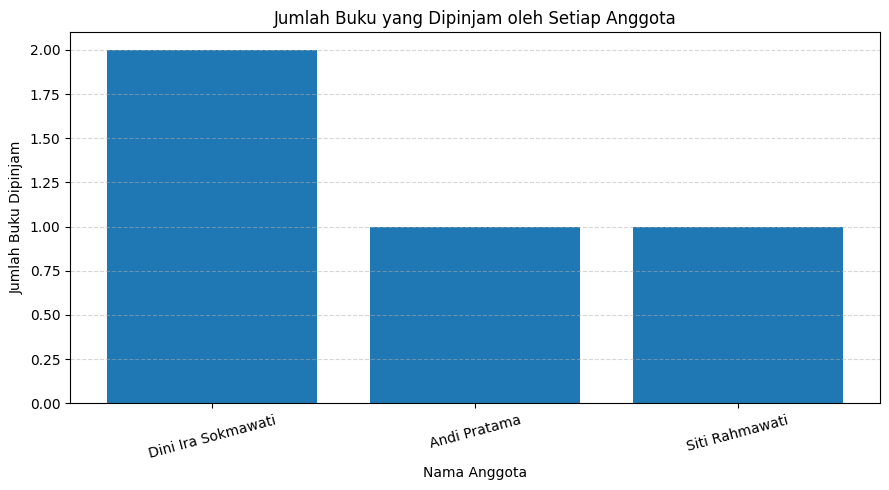

In [ ]:

# Visualisasi jumlah buku yang dipinjam setiap anggota

plt.figure(figsize=(9, 5))

plt.bar(
    df_group['Nama_Anggota'],
    df_group['Jumlah_Buku_Dipinjam']
)

plt.title('Jumlah Buku yang Dipinjam oleh Setiap Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Buku Dipinjam')

plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


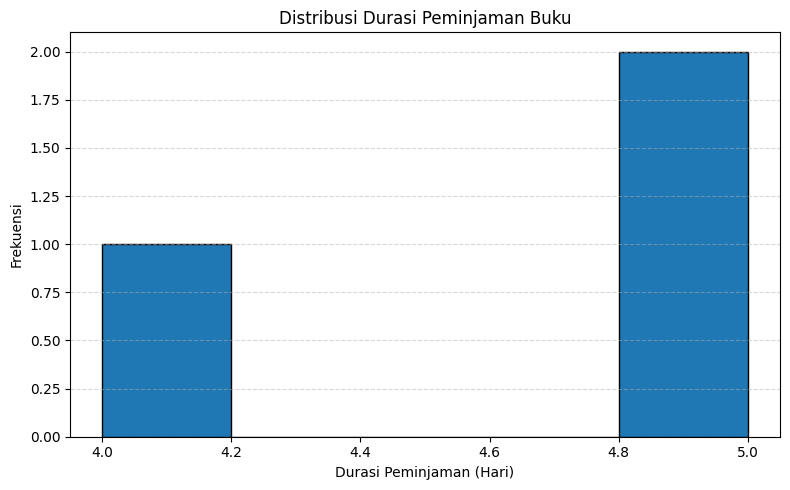

In [ ]:

# Mengambil data durasi yang sudah memiliki tanggal kembali

durasi = df['Durasi_Peminjaman'].dropna()

# Membuat histogram durasi peminjaman

plt.figure(figsize=(8, 5))

plt.hist(
    durasi,
    bins=5,
    edgecolor='black'
)

plt.title('Distribusi Durasi Peminjaman Buku')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.ylabel('Frekuensi')

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


**Hasil Visualisasi Data**

Visualisasi data dilakukan menggunakan library Matplotlib untuk menggambarkan hasil analisis peminjaman buku.

Grafik pertama berupa diagram batang yang menunjukkan jumlah buku yang dipinjam oleh masing-masing anggota. Berdasarkan grafik tersebut, Dini Ira Sokmawati memiliki jumlah peminjaman terbanyak, yaitu 2 buku, sedangkan Andi Pratama dan Siti Rahmawati masing-masing meminjam 1 buku.

Grafik kedua berupa histogram yang menggambarkan distribusi durasi peminjaman buku. Berdasarkan hasil perhitungan, terdapat tiga transaksi yang telah selesai dengan durasi peminjaman antara 4 hingga 5 hari. Sementara itu, satu transaksi tidak dimasukkan ke dalam histogram karena buku tersebut belum dikembalikan.

Dengan adanya visualisasi ini, informasi peminjaman buku dapat dipahami dengan lebih mudah melalui penyajian grafik.